# 11 — Circuit cutting with `qiskit-addon-cutting`

**Circuit cutting** estimates expectation values of a circuit that does not fit the device. The circuit may be too *wide*
(too many qubits), or too *deep* for the device connectivity. The method has two kinds of cuts:

* a **gate cut** replaces a two-qubit gate by a set of local operations;
* a **wire cut** replaces one qubit wire at one point in time by a measurement and a state preparation.

After the cuts, the circuit splits into smaller pieces. We run many variants of these pieces (the **subexperiments**).
A classical post-processing step then combines their results with a **quasi-probability decomposition (QPD)**. The [explanatory material](https://qiskit.github.io/qiskit-addon-cutting/explanation/index.html) of the package describes the method [1].

The cost is a **sampling overhead**: more shots are needed for the same statistical error. The overhead grows exponentially
with the number of cuts.

The `qiskit-addon-cutting` package (version 0.10.0 here, formerly the *Circuit Knitting Toolbox*) provides these functions
(see the [API reference](https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.html) [7] and the [IBM Quantum API page](https://quantum.cloud.ibm.com/docs/en/api/qiskit-addon-cutting/qiskit-addon-cutting) [9]):

| function / class | purpose |
|---|---|
| `partition_problem`, `cut_gates` | mark the gates to cut; split a circuit and its observables into labelled partitions |
| `cut_wires`, `expand_observables`, `CutWire`, `Move` | wire cutting |
| `generate_cutting_experiments` | build the subexperiments and their QPD coefficients |
| `reconstruct_expectation_values` | combine the sampler results into expectation values |
| `find_cuts`, `OptimizationParameters`, `DeviceConstraints` | automatic search for cuts with a low overhead |

**Based on**

* [Explanatory material: circuit cutting](https://qiskit.github.io/qiskit-addon-cutting/explanation/index.html) [1] (Section 1)
* [Tutorial: Gate Cutting to Reduce Circuit Width](https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html) [2] (Section 3)
* [Tutorial: Gate Cutting to Reduce Circuit Depth](https://qiskit.github.io/qiskit-addon-cutting/tutorials/02_gate_cutting_to_reduce_circuit_depth.html) [3] (Section 5)
* [Tutorial: Wire Cutting Phrased as a Two-Qubit Move Instruction](https://qiskit.github.io/qiskit-addon-cutting/tutorials/03_wire_cutting_via_move_instruction.html) [4] and the [how-to guide on `CutWire`](https://qiskit.github.io/qiskit-addon-cutting/how-tos/how_to_specify_cut_wires.html) [6] (Section 6)
* [Tutorial: Automatically find cuts](https://qiskit.github.io/qiskit-addon-cutting/tutorials/04_automatic_cut_finding.html) [5] (Section 7)
* [API reference](https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.html) [7], [`qpd` module API](https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.qpd.html) [8] and the [IBM Quantum circuit-cutting API page](https://quantum.cloud.ibm.com/docs/en/api/qiskit-addon-cutting/qiskit-addon-cutting) [9]

The sizes, observables and analysis are adapted for a CPU simulator. The comparisons in Sections 4 and 6 are our own additions.

Install:

```bash
pip install qiskit-addon-cutting
```

**Contents**

1. Theory: quasi-probability decomposition and sampling overhead
2. Setup and the sampling overhead of single cuts
3. Gate cutting to reduce circuit **width** (`partition_problem` → `generate_cutting_experiments` → Aer `SamplerV2` → `reconstruct_expectation_values`)
4. Shot noise: the overhead in practice
5. Gate cutting to reduce circuit **depth** on a fake backend (`cut_gates`)
6. Wire cutting (`CutWire` + `cut_wires` / `expand_observables`, and the explicit `Move` instruction)
7. Automatic cut finding (`find_cuts`)
8. Summary, notes on the installed version, references

## 1. Theory: quasi-probability decomposition

Let $U$ be a non-local gate. Its noiseless action is the channel $\mathcal U(\rho)=U\rho U^\dagger$. A **QPD** writes this
channel as a linear combination of *local* channels $\mathcal F_i$. Each $\mathcal F_i$ is a product of operations on the two
sides. It may contain mid-circuit measurements.

$$
\mathcal U = \sum_i a_i\,\mathcal F_i ,\qquad a_i\in\mathbb R .
$$

Some coefficients $a_i$ are negative, so this sum is not a probability mixture. We define

$$
\kappa=\sum_i |a_i|,\qquad p_i = |a_i|/\kappa .
$$

Then $\langle O\rangle = \kappa \sum_i p_i\,\mathrm{sign}(a_i)\,\langle O\rangle_{\mathcal F_i}$. We estimate this value by
**sampling**:

1. pick term $i$ with probability $p_i$;
2. run it and weight the outcome by $\kappa\,\mathrm{sign}(a_i)$.

The factor $\kappa$ multiplies the standard deviation. For the same error we therefore need $\kappa^2$ times more shots.
This factor is the **sampling overhead**. For $n$ cuts with independent QPDs, the overheads multiply:

$$
\text{overhead} = \prod_{j=1}^{n}\kappa_j^2 .
$$

The package uses decompositions with local operations only (**LO**: no classical communication between the pieces).
Typical values are:

| cut | $\kappa$ | overhead $\kappa^2$ |
|---|---|---|
| CX, CZ, CY, CH, ECR (any Clifford 2-qubit gate equivalent to CX) | 3 | 9 |
| $R_{ZZ}(\theta)$, $R_{XX}(\theta)$, $R_{YY}(\theta)$ (Qiskit angle convention) | $1+2\lvert\sin\theta\rvert$ | $(1+2\lvert\sin\theta\rvert)^2$ |
| SWAP, iSWAP | 7 | 49 |
| wire cut (`Move`, LO) | 4 | 16 |

The [explanatory material](https://qiskit.github.io/qiskit-addon-cutting/explanation/index.html) [1] explains the LO setting and the settings with classical communication (LOCC),
and it derives the overhead of a cut $R_{ZZ}$ gate.

A wire cut of qubit $q$ uses the identity $\rho=\tfrac12\sum_{P\in\{I,X,Y,Z\}}\mathrm{Tr}(P\rho)P$. The first piece measures $q$
in a Pauli basis. The second piece prepares an eigenstate of that Pauli on a *new* qubit.

The package has two modes:

* **exact weights** (`num_samples=np.inf`): each term, or each product of terms over all cuts, appears once with its exact
  coefficient. Use this mode when the number of terms is small.
* **sampled weights** (finite `num_samples`): the terms with the largest weights are kept exactly, and the other terms are sampled.

## 2. Setup and the overhead of single cuts

All circuits here are small: at most 7 qubits, and at most 5 qubits per piece. Aer runs on the CPU with 2 threads.
A GPU gives no speed-up for 3-qubit pieces. The next cell also shows how to select the GPU device.

In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit.library import efficient_su2, CXGate, CZGate, SwapGate, RZZGate, CRZGate
from qiskit.quantum_info import SparsePauliOp, PauliList, Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

from qiskit_addon_cutting import (
    partition_problem, cut_gates, generate_cutting_experiments, reconstruct_expectation_values,
    cut_wires, expand_observables, find_cuts, OptimizationParameters, DeviceConstraints,
)
from qiskit_addon_cutting.instructions import CutWire, Move
from qiskit_addon_cutting.qpd import qpdbasis_from_instruction

from importlib.metadata import version
import qiskit, qiskit_aer
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-addon-cutting", version("qiskit-addon-cutting"))

# Device choice: small subcircuits run faster on the CPU than on the GPU
print("Aer devices:", AerSimulator().available_devices())
DEVICE = "CPU"            # set to "GPU" for wide circuits if "GPU" is in available_devices()
backend_options = {"device": DEVICE, "max_parallel_threads": 2}
sampler = SamplerV2(default_shots=4096, seed=42, options={"backend_options": backend_options})
T_START = time.perf_counter()

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-addon-cutting 0.10.0
Aer devices: ('CPU', 'GPU')


[`qpdbasis_from_instruction`](https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.qpd.html) [8] returns the `QPDBasis` that the package uses for a gate. Its attributes `kappa` and `overhead`
($=\kappa^2$) are the numbers in the table above. For continuous rotations, the overhead depends on the angle. It goes to 1
as $\theta\to0$. Cuts of *small-angle* gates, for example in Trotter steps, are therefore cheap.

cx    []          kappa =  3.000   overhead =   9.000   #terms = 6
cz    []          kappa =  3.000   overhead =   9.000   #terms = 6
swap  []          kappa =  7.000   overhead =  49.000   #terms = 58
rzz   [1.571]     kappa =  3.000   overhead =   9.000   #terms = 6
rzz   [0.2]       kappa =  1.397   overhead =   1.953   #terms = 6
crz   [0.2]       kappa =  1.200   overhead =   1.439   #terms = 6
move  []          kappa =  4.000   overhead =  16.000   #terms = 8


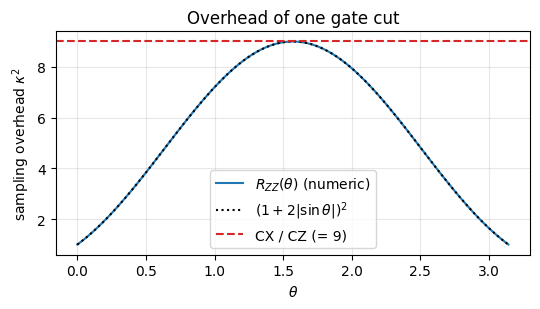

In [2]:
for g in [CXGate(), CZGate(), SwapGate(), RZZGate(np.pi / 2), RZZGate(0.2), CRZGate(0.2), Move()]:
    b = qpdbasis_from_instruction(g)
    print(f"{g.name:5s} {str([round(float(p), 3) for p in g.params]):10s}  kappa = {b.kappa:6.3f}"
          f"   overhead = {b.overhead:7.3f}   #terms = {len(b.maps)}")

thetas = np.linspace(0, np.pi, 121)
ov = [qpdbasis_from_instruction(RZZGate(t)).overhead for t in thetas]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(thetas, ov, label=r"$R_{ZZ}(\theta)$ (numeric)")
ax.plot(thetas, (1 + 2 * np.abs(np.sin(thetas))) ** 2, "k:", label=r"$(1+2|\sin\theta|)^2$")
ax.axhline(9, color="C3", ls="--", label="CX / CZ (= 9)")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"sampling overhead $\kappa^2$"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Overhead of one gate cut")
plt.tight_layout(); plt.show()

> **Angle convention.** Qiskit defines $R_{ZZ}(\theta)=e^{-i\theta Z\otimes Z/2}$. The overhead has its maximum of 9 at $\theta=\pi/2$.
> At this angle, $R_{ZZ}$ equals CZ up to local gates. The overhead returns to 1 at $\theta=\pi$, because $R_{ZZ}(\pi)=-iZ\otimes Z$ is a *local* operation.
> A controlled rotation $CR_Z(\theta)$ equals $R_{ZZ}(\theta/2)$ up to local gates, so its overhead is $(1+2|\sin(\theta/2)|)^2$.

## 3. Gate cutting to reduce circuit width

This section follows the tutorial [Gate Cutting to Reduce Circuit Width](https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html) [2]. The circuit is a 6-qubit hardware-efficient
`efficient_su2` ansatz with linear entanglement, 2 repetitions and fixed random angles. The observables are $Z$-type Pauli strings.

We assume a device with only 3 qubits. The qubits get the labels `A` = {0,1,2} and `B` = {3,4,5}. Each CX
between qubits 2 and 3 crosses the boundary, so we cut it.

OrderedDict([('ry', 18), ('rz', 18), ('cx', 10)])


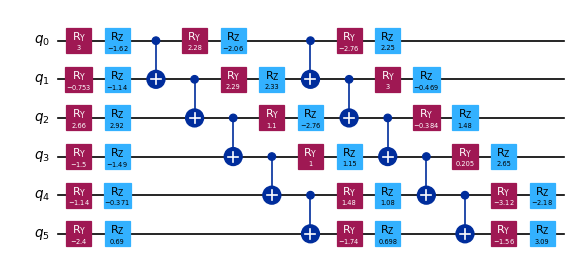

In [3]:
n = 6
qc = efficient_su2(n, entanglement="linear", reps=2)
rng = np.random.default_rng(1234)
qc.assign_parameters(rng.uniform(-np.pi, np.pi, qc.num_parameters), inplace=True)

# Pauli labels: rightmost character = qubit 0
observables = PauliList(["ZZIIII", "IZZIII", "IIZZII", "IIIZZI", "IIIIZZ", "ZIIIIZ", "ZZZZZZ"])
psi = Statevector(qc)
exact = np.array([psi.expectation_value(SparsePauliOp(p)).real for p in observables])
print(qc.count_ops())
qc.draw("mpl", fold=-1, scale=0.6)

cut gates          : 2 -> [np.float64(9.0), np.float64(9.0)]
total overhead     : 81.0
sub-observables    : {'A': PauliList(['III', 'III', 'ZII', 'ZZI', 'IZZ', 'IIZ', 'ZZZ']), 'B': PauliList(['ZZI', 'IZZ', 'IIZ', 'III', 'III', 'ZII', 'ZZZ'])}


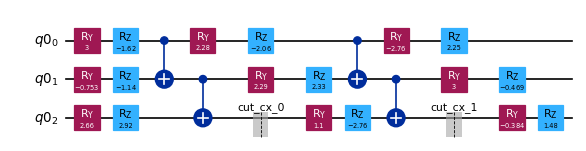

In [4]:
partitioned = partition_problem(circuit=qc, partition_labels="AAABBB", observables=observables)
subcircuits, bases, subobservables = partitioned.subcircuits, partitioned.bases, partitioned.subobservables

print("cut gates          :", len(bases), "->", [b.overhead for b in bases])
print("total overhead     :", np.prod([b.overhead for b in bases]))
print("sub-observables    :", dict(subobservables))
subcircuits["A"].draw("mpl", fold=-1, scale=0.6)

Each cut CX appears as a `qpd_1q` placeholder in each subcircuit. The placeholder holds the QPD basis. The two halves of
one cut gate have the same `id`. The observable `ZIIIIZ` (qubits 0 and 5) splits into `IIZ` on `A` and `ZII` on `B`.

`generate_cutting_experiments` does three things:

1. it replaces each placeholder by one of the QPD terms;
2. it adds the measurements for the observables (one group of commuting observables at a time);
3. it returns the coefficient $a_i$ of each joint term.

With 2 CX cuts of 6 terms each, exact weights give $6^2 = 36$ subexperiments per partition.

{'A': 36, 'B': 36} | #coefficients: 36
sum |coeff| = 8.999999999999998  (= kappa_total = 3*3)
weight types: {'EXACT'}


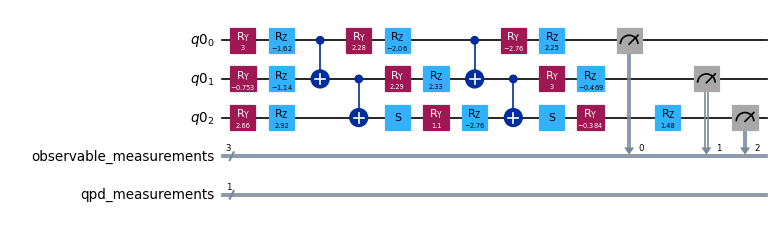

In [5]:
subexperiments, coefficients = generate_cutting_experiments(
    circuits=subcircuits, observables=subobservables, num_samples=np.inf)
print({k: len(v) for k, v in subexperiments.items()}, "| #coefficients:", len(coefficients))
print("sum |coeff| =", sum(abs(c) for c, _ in coefficients), " (= kappa_total = 3*3)")
print("weight types:", {w.name for _, w in coefficients})
subexperiments["A"][7].draw("mpl", fold=-1, scale=0.6)

Each subexperiment stores the observable measurements in the classical register `observable_measurements`. It stores the
mid-circuit QPD measurements in the register `qpd_measurements`. We run the subexperiments with the **Aer `SamplerV2`**.
The circuits contain only standard gates, so the ideal simulator does not need transpilation. For a backend target, we must
transpile them first (Section 5). The results go back to the package as a dict `{label: PrimitiveResult}`.

In [6]:
t0 = time.perf_counter()
results = {label: sampler.run(subsystem_subexpts, shots=4096).result()
           for label, subsystem_subexpts in subexperiments.items()}
reconstructed = np.array(reconstruct_expectation_values(results, coefficients, subobservables))
print(f"sampling + reconstruction: {time.perf_counter() - t0:.2f} s")

for p, e, r in zip(observables, exact, reconstructed):
    print(f"{str(p):8s} exact = {e:+.4f}   cut = {r:+.4f}   |err| = {abs(e - r):.4f}")

sampling + reconstruction: 2.23 s
ZZIIII   exact = -0.0032   cut = -0.0100   |err| = 0.0067
IZZIII   exact = +0.4269   cut = +0.4404   |err| = 0.0135
IIZZII   exact = +0.0057   cut = +0.0160   |err| = 0.0102
IIIZZI   exact = -0.1616   cut = -0.1669   |err| = 0.0053
IIIIZZ   exact = +0.1687   cut = +0.1502   |err| = 0.0186
ZIIIIZ   exact = -0.0455   cut = -0.0385   |err| = 0.0070
ZZZZZZ   exact = -0.0024   cut = +0.0037   |err| = 0.0060


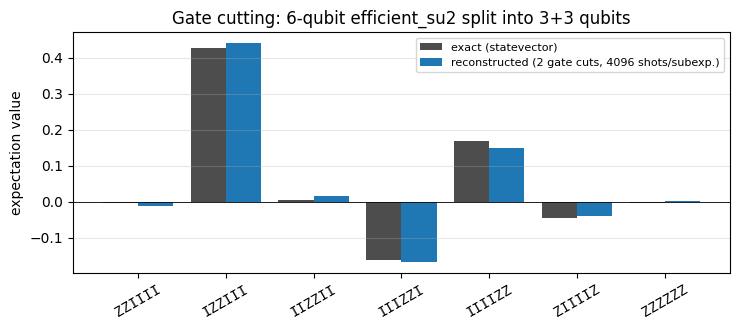

In [7]:
def compare_plot(labels, exact_vals, series, title):
    x = np.arange(len(labels)); w = 0.8 / (1 + len(series))
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.bar(x - 0.4 + w / 2, exact_vals, w, label="exact (statevector)", color="0.3")
    for k, (name, vals) in enumerate(series.items(), start=1):
        ax.bar(x - 0.4 + w / 2 + k * w, vals, w, label=name)
    ax.set_xticks(x); ax.set_xticklabels([str(l) for l in labels], rotation=30, family="monospace")
    ax.axhline(0, color="k", lw=.6); ax.set_ylabel("expectation value"); ax.set_title(title)
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

compare_plot(observables, exact, {"reconstructed (2 gate cuts, 4096 shots/subexp.)": reconstructed},
             "Gate cutting: 6-qubit efficient_su2 split into 3+3 qubits")

`partition_problem` does not require observables. Another option is to call `cut_gates` on selected gate indices.
`partition_problem` with `partition_labels=None` then finds the connected components.
For a `SparsePauliOp` with coefficients, we cut its `.paulis` and then combine the results with the
coefficients: $\langle H\rangle=\sum_k c_k\langle P_k\rangle$.

In [8]:
H = SparsePauliOp(observables, coeffs=[1.0, 0.5, 0.25, 0.5, 1.0, 0.3, -0.2])
print("<H> exact     :", psi.expectation_value(H).real)
print("<H> from cuts :", np.dot(H.coeffs.real, reconstructed))

<H> exact     : 0.2864076788406811
<H> from cuts : 0.26866659820079797


## 4. Shot noise: the overhead in practice

The reconstructed estimator is unbiased. Its variance is about $\kappa^2$ times larger than for the uncut circuit with the
same total number of shots. To test this, we repeat the experiment for several shot budgets and random seeds. We compare two RMS errors:

* the RMS error of the cut estimate;
* the RMS error of direct sampling of the uncut 6-qubit circuit with the **same total** number of shots.

With two CX cuts, $\kappa^2=81$.

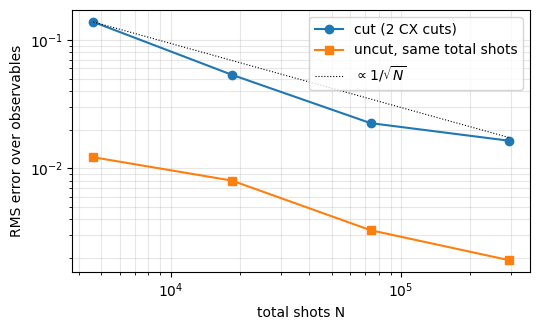

empirical variance ratio cut/uncut: [129.8  44.9  47.   73.4]  (upper bound kappa^2 = 81)


In [9]:
def rms_error_cut(shots, seed):
    s = SamplerV2(seed=seed, options={"backend_options": backend_options})
    res = {lab: s.run(subexperiments[lab], shots=shots).result() for lab in subexperiments}
    rec = np.array(reconstruct_expectation_values(res, coefficients, subobservables))
    return np.sqrt(np.mean((rec - exact) ** 2))

def z_expvals(counts, paulis):
    # <P> for Z/I-type Paulis from a counts dict (bitstring: rightmost char = clbit 0)
    shots = sum(counts.values()); out = []
    for p in paulis:
        mask = [i for i, ch in enumerate(str(p)[::-1]) if ch == "Z"]
        out.append(sum(c * (-1) ** sum(int(b[::-1][i]) for i in mask) for b, c in counts.items()) / shots)
    return np.array(out)

qc_meas = qc.copy(); qc_meas.measure_all()

def rms_error_uncut(total_shots, seed):
    s = SamplerV2(seed=seed, options={"backend_options": backend_options})
    counts = s.run([qc_meas], shots=int(total_shots)).result()[0].data.meas.get_counts()
    return np.sqrt(np.mean((z_expvals(counts, observables) - exact) ** 2))

n_sub = sum(len(v) for v in subexperiments.values())
shot_list = [64, 256, 1024, 4096]
seeds = range(4)
err_cut = [np.mean([rms_error_cut(s, sd) for sd in seeds]) for s in shot_list]
err_unc = [np.mean([rms_error_uncut(s * n_sub, sd) for sd in seeds]) for s in shot_list]

tot = np.array(shot_list) * n_sub
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.loglog(tot, err_cut, "o-", label="cut (2 CX cuts)")
ax.loglog(tot, err_unc, "s-", label="uncut, same total shots")
ax.loglog(tot, err_cut[0] * np.sqrt(tot[0] / tot), "k:", lw=.8, label=r"$\propto 1/\sqrt{N}$")
ax.set_xlabel("total shots N"); ax.set_ylabel("RMS error over observables"); ax.legend(); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()
ratio = (np.array(err_cut) / np.array(err_unc)) ** 2
print("empirical variance ratio cut/uncut:", np.round(ratio, 1), " (upper bound kappa^2 = 81)")

With only four seeds, the measured variance ratio varies strongly. Its size is close to $\kappa^2=81$.
In general, $\kappa^2$ is a worst-case value, and some observables have a smaller overhead.

Both curves follow $1/\sqrt N$, with a constant gap between them. This gap is the sampling overhead.
With $n$ CX cuts, the gap grows as $3^n$ in the error, or $9^n$ in the number of shots.

## 5. Gate cutting to reduce circuit depth (fake backend)

This section follows the tutorial [Gate Cutting to Reduce Circuit Depth](https://qiskit.github.io/qiskit-addon-cutting/tutorials/02_gate_cutting_to_reduce_circuit_depth.html) [3]. A **circular** `efficient_su2` on 4 qubits
has a CX between qubits 3 and 0 in each repetition. `FakeManilaV2` has a **linear** coupling map 0–1–2–3–4. The transpiler must
therefore add SWAP gates for this long-range gate.

If we cut these gates instead, each subexperiment fits the line without SWAP gates. We do **not** split the circuit into
partitions here. The subexperiments are still 4-qubit circuits, but they are shallower.

coupling map: [[0, 1], [1, 0], [1, 2], [2, 1], [2, 3], [3, 2], [3, 4], [4, 3]]
gates to cut: [8, 20]
overhead: 81.0


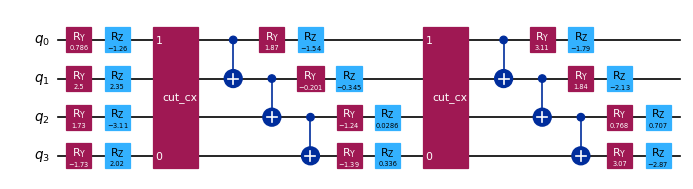

In [10]:
fake = FakeManilaV2()
print("coupling map:", fake.coupling_map)

qc_c = efficient_su2(4, entanglement="circular", reps=2)
qc_c.assign_parameters(np.random.default_rng(7).uniform(-np.pi, np.pi, qc_c.num_parameters), inplace=True)
obs_c = PauliList(["ZZII", "IZZI", "IIZZ", "ZIIZ", "ZIZI", "ZZZZ"])
exact_c = np.array([Statevector(qc_c).expectation_value(SparsePauliOp(p)).real for p in obs_c])

# indices of the long-range CX(3,0) gates
long_range = [i for i, ci in enumerate(qc_c.data)
              if ci.operation.num_qubits == 2 and {qc_c.find_bit(q).index for q in ci.qubits} == {0, 3}]
print("gates to cut:", long_range)
qc_cut, bases_c = cut_gates(qc_c, long_range)
print("overhead:", np.prod([b.overhead for b in bases_c]))
qc_cut.draw("mpl", fold=-1, scale=0.6)

In [11]:
pm = generate_preset_pass_manager(optimization_level=1, backend=fake, initial_layout=[0, 1, 2, 3], seed_transpiler=1)

subexp_c, coeffs_c = generate_cutting_experiments(qc_cut, obs_c, num_samples=np.inf)
isa_subexp = pm.run(subexp_c)

meas_uncut = qc_c.copy(); meas_uncut.measure_all()
isa_uncut = pm.run(meas_uncut)
print(f"uncut   : depth {isa_uncut.depth():3d}, 2q gates {isa_uncut.count_ops().get('cx', 0)}")
d = [c.depth() for c in isa_subexp]; c2 = [c.count_ops().get("cx", 0) for c in isa_subexp]
print(f"cut     : {len(isa_subexp)} subexperiments, mean depth {np.mean(d):.1f} (max {max(d)}), "
      f"mean 2q gates {np.mean(c2):.1f}")

uncut   : depth  41, 2q gates 32
cut     : 36 subexperiments, mean depth 21.3 (max 27), mean 2q gates 6.0


Next, we run both versions in a **noisy** simulation of the fake backend. `SamplerV2.from_backend` builds an Aer sampler with the
noise model of the backend (gate *and* readout errors) and its basis gates. The uncut reference uses the same noisy sampler
and the same total number of shots. We compute its $Z$-type expectation values from the counts.

ideal cut    mean |err| = 0.0081
noisy uncut  mean |err| = 0.0208
noisy cut    mean |err| = 0.0239


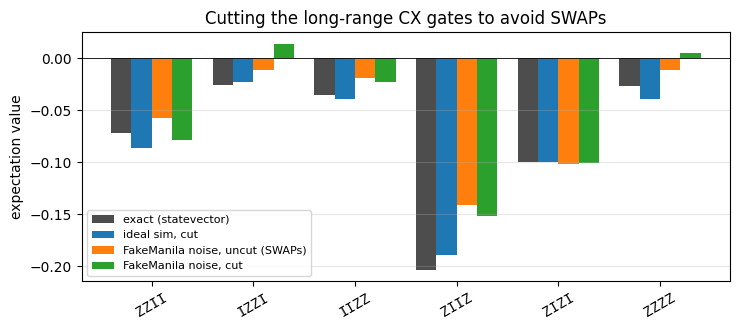

In [12]:
noisy_sampler = SamplerV2.from_backend(fake, seed=11, options={"backend_options": {"max_parallel_threads": 2}})
res_c = noisy_sampler.run(isa_subexp, shots=8192).result()
rec_noisy_cut = np.array(reconstruct_expectation_values(res_c, coeffs_c, obs_c))

# measure_all() maps virtual qubit i to clbit i, so counts are in virtual-qubit order
counts_uncut = noisy_sampler.run([isa_uncut], shots=8192 * len(isa_subexp)).result()[0].data.meas.get_counts()
noisy_uncut = z_expvals(counts_uncut, obs_c)

ideal_res = sampler.run(subexp_c, shots=8192).result()
rec_ideal_cut = np.array(reconstruct_expectation_values(ideal_res, coeffs_c, obs_c))

for name, v in [("ideal cut", rec_ideal_cut), ("noisy uncut", noisy_uncut), ("noisy cut", rec_noisy_cut)]:
    print(f"{name:12s} mean |err| = {np.mean(np.abs(v - exact_c)):.4f}")
compare_plot(obs_c, exact_c, {"ideal sim, cut": rec_ideal_cut, "FakeManila noise, uncut (SWAPs)": noisy_uncut,
                              "FakeManila noise, cut": rec_noisy_cut},
             "Cutting the long-range CX gates to avoid SWAPs")

The cut removes the SWAP gates. Each subexperiment has about 5 times fewer noisy CX gates and about half the depth.
**This does not by itself give a more accurate result.** The reconstruction multiplies the remaining gate and readout errors
by coefficients up to $\kappa=9$. This includes the errors of the extra QPD mid-circuit measurements.

In this small, shallow example, the cut and uncut noisy results are similar. Cutting helps when the SWAP overhead is the main
source of error, for example in deeper circuits or on heavy-hex lattices. In practice, cutting is combined with error mitigation,
for example `mthree` readout mitigation of the sampler counts, and the $\kappa^2$ shot cost is accepted.

## 6. Wire cutting

Gate cutting is cheap when a pair of qubits interacts only *once* across the boundary. Consider a "messenger" qubit that first
interacts with several qubits on the left and then with several qubits on the right. In this case, one cut of the messenger wire
($\kappa^2=16$) costs less than cuts of all the crossing gates.

Version 0.10 has two equivalent ways to do this:

1. **Mark the cut** with the single-qubit `CutWire` instruction, as in the [how-to guide on `CutWire`](https://qiskit.github.io/qiskit-addon-cutting/how-tos/how_to_specify_cut_wires.html) [6]. `cut_wires` then replaces it by a two-qubit `Move`
   to a *new* qubit. `expand_observables` adds identities on the new qubits to the observables.
2. **Build the circuit directly** with an extra qubit and an explicit `Move(source, new_qubit)` instruction
   (tutorial [Wire Cutting Phrased as a Two-Qubit Move Instruction](https://qiskit.github.io/qiskit-addon-cutting/tutorials/03_wire_cutting_via_move_instruction.html) [4]).

In both cases, `partition_problem` sees a two-qubit `Move` gate across the partitions and cuts it like a gate.

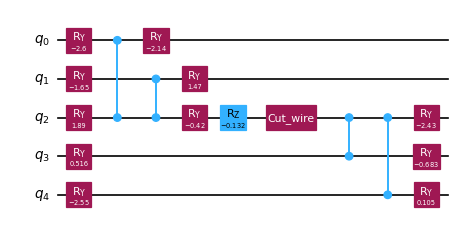

In [13]:
def messenger_circuit(theta):
    qc = QuantumCircuit(5)
    for q in range(5):
        qc.ry(theta[q], q)
    # messenger = qubit 2: two CZs with the left block {0,1} ...
    qc.cz(2, 0); qc.cz(2, 1); qc.ry(theta[5], 2); qc.rz(theta[6], 2)
    qc.append(CutWire(), [2])                     # <- the wire cut
    # ... then two CZs with the right block {3,4}
    qc.cz(2, 3); qc.cz(2, 4)
    for q in range(5):
        qc.ry(theta[7 + q], q)
    return qc

theta = np.random.default_rng(3).uniform(-np.pi, np.pi, 12)
qc_w = messenger_circuit(theta)
obs_w = PauliList(["IIIZZ", "IIZZI", "IZZII", "ZZIII", "ZIIIZ", "ZZZZZ", "IXZXI"])

# exact reference: same circuit without the CutWire marker
qc_w_plain = qc_w.copy(); qc_w_plain.data = [ci for ci in qc_w.data if ci.operation.name != "cut_wire"]
exact_w = np.array([Statevector(qc_w_plain).expectation_value(SparsePauliOp(p)).real for p in obs_w])
qc_w.draw("mpl", fold=-1, scale=0.6)

5 -> 6 qubits
expanded observables: ['IIIIZZ', 'IIZIZI', 'IZZIII', 'ZZIIII', 'ZIIIIZ', 'ZZZIZZ', 'IXZIXI']


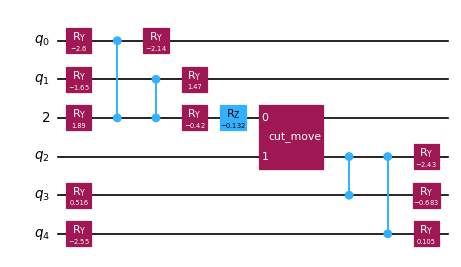

In [14]:
qc_w_moved = cut_wires(qc_w)                                  # CutWire -> Move onto a new qubit
obs_w_exp = expand_observables(obs_w, qc_w, qc_w_moved)         # pad observables for the new qubit
print(qc_w.num_qubits, "->", qc_w_moved.num_qubits, "qubits")
print("expanded observables:", obs_w_exp)
qc_w_moved.draw("mpl", fold=-1, scale=0.6)

partitions: {0: 3, 1: 3} | overhead: [np.float64(16.0)] | sub-observables: {0: PauliList(['IZZ', 'IZI', 'III', 'III', 'IIZ', 'IZZ', 'IXI']), 1: PauliList(['III', 'IIZ', 'IZZ', 'ZZI', 'ZII', 'ZZZ', 'IXZ'])}
{0: 16, 1: 16}


gate-cut alternative overhead: 81.0


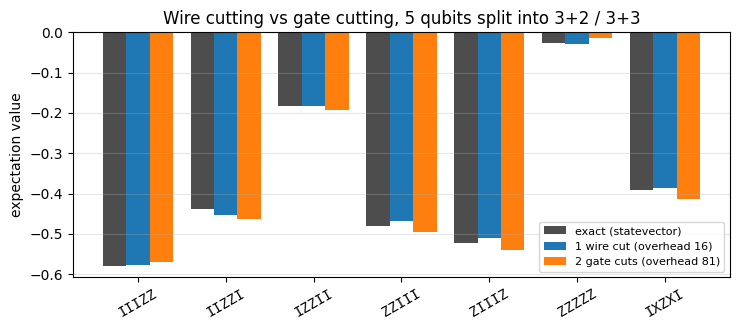

mean |err| wire: 0.0078  gate: 0.0151


In [15]:
pp_w = partition_problem(qc_w_moved, observables=obs_w_exp)    # labels found automatically
print("partitions:", {k: v.num_qubits for k, v in pp_w.subcircuits.items()},
      "| overhead:", [b.overhead for b in pp_w.bases], "| sub-observables:", dict(pp_w.subobservables))

sub_w, coeffs_w = generate_cutting_experiments(pp_w.subcircuits, pp_w.subobservables, num_samples=np.inf)
print({k: len(v) for k, v in sub_w.items()})
res_w = {k: sampler.run(v, shots=4096).result() for k, v in sub_w.items()}
rec_w = np.array(reconstruct_expectation_values(res_w, coeffs_w, pp_w.subobservables))

# For comparison: gate-cut the 2 CZs crossing between {0,1,2} and {3,4} instead (overhead 81)
pp_g = partition_problem(qc_w_plain, partition_labels="AAABB", observables=obs_w)
print("gate-cut alternative overhead:", np.prod([b.overhead for b in pp_g.bases]))
sub_g, coeffs_g = generate_cutting_experiments(pp_g.subcircuits, pp_g.subobservables, num_samples=np.inf)
res_g = {k: sampler.run(v, shots=4096).result() for k, v in sub_g.items()}
rec_g = np.array(reconstruct_expectation_values(res_g, coeffs_g, pp_g.subobservables))

compare_plot(obs_w, exact_w, {"1 wire cut (overhead 16)": rec_w, "2 gate cuts (overhead 81)": rec_g},
             "Wire cutting vs gate cutting, 5 qubits split into 3+2 / 3+3")
print("mean |err| wire:", np.mean(np.abs(rec_w - exact_w)).round(4), " gate:", np.mean(np.abs(rec_g - exact_w)).round(4))

**Explicit `Move` version.** We can also write the circuit directly. Here the new qubit is qubit 5, and we map the
observables by hand. `Move(a, b)` resets `b` and then swaps `a` and `b`, so the state of `a` continues on `b`.

In [16]:
qc_m = QuantumCircuit(6)
for q in range(5):
    qc_m.ry(theta[q], q)
qc_m.cz(2, 0); qc_m.cz(2, 1); qc_m.ry(theta[5], 2); qc_m.rz(theta[6], 2)
qc_m.append(Move(), [2, 5])                       # qubit 2's state continues on qubit 5
qc_m.cz(5, 3); qc_m.cz(5, 4)
for q in [0, 1, 3, 4]:
    qc_m.ry(theta[7 + q], q)
qc_m.ry(theta[9], 5)                              # final rotation of the messenger, now on qubit 5

def remap(p):  # observable on original qubit 2 now lives on qubit 5 (after the move)
    s = list(str(p)[::-1]) + ["I"]                 # little-endian list, add qubit 5
    s[5], s[2] = s[2], "I"
    return "".join(s[::-1])
obs_m = PauliList([remap(p) for p in obs_w])

pp_m = partition_problem(qc_m, partition_labels="AAABBB", observables=obs_m)
sub_m, coeffs_m = generate_cutting_experiments(pp_m.subcircuits, pp_m.subobservables, num_samples=np.inf)
res_m = {k: sampler.run(v, shots=4096).result() for k, v in sub_m.items()}
rec_m = np.array(reconstruct_expectation_values(res_m, coeffs_m, pp_m.subobservables))
print("observables:", obs_m)
exact_m = np.array([Statevector(qc_m).expectation_value(SparsePauliOp(p)).real for p in obs_m])
print("explicit-Move circuit reproduces the exact values:", np.allclose(exact_m, exact_w))
print("Move version mean |err|:", np.mean(np.abs(rec_m - exact_w)).round(4))

observables: ['IIIIZZ', 'ZIIIZI', 'ZIZIII', 'IZZIII', 'IZIIIZ', 'ZZZIZZ', 'ZIXIXI']
explicit-Move circuit reproduces the exact values: True
Move version mean |err|: 0.0146


## 7. Automatic cut finding

This section follows the tutorial [Automatically find cuts](https://qiskit.github.io/qiskit-addon-cutting/tutorials/04_automatic_cut_finding.html) [5], with a 7-qubit `efficient_su2`.

Manual choice of cuts becomes tedious for larger circuits. [`find_cuts`](https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.html) [7] searches for a set of gate and wire cuts so that each piece
has at most `DeviceConstraints.qubits_per_subcircuit` qubits. It minimizes the total overhead with a best-first search over
LO cuts.

* `OptimizationParameters(seed, max_gamma, max_backjumps, gate_lo=True, wire_lo=True)` switches gate cuts and wire cuts on or off.
  It also limits the search. If the search reaches a limit, the result is a greedy upper bound, and `metadata["minimum_reached"]` is `False`.
* `find_cuts` returns a circuit with `TwoQubitQPDGate`s (gate cuts) and `CutWire`s (wire cuts). It also returns `metadata` with the
  list of cuts and the `sampling_overhead` ($=\gamma^2$).

The input circuit may contain only 1- and 2-qubit gates. Gates on 3 qubits, such as the Toffoli gate, are not allowed.

Found 2 cuts: [('Gate Cut', 17), ('Gate Cut', 37)]
sampling overhead = 81, minimum reached = True


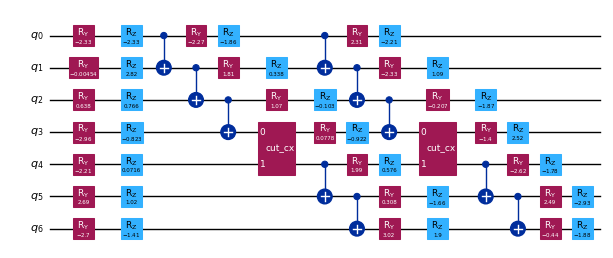

In [17]:
qc7 = efficient_su2(7, entanglement="linear", reps=2)
qc7.assign_parameters(np.random.default_rng(11).uniform(-np.pi, np.pi, qc7.num_parameters), inplace=True)
obs7 = PauliList(["ZIIIIII", "IIIZIII", "IIIIIIZ", "ZZIIIII", "IIIZZII", "ZIIIIIZ"])
exact7 = np.array([Statevector(qc7).expectation_value(SparsePauliOp(p)).real for p in obs7])

opt = OptimizationParameters(seed=111, gate_lo=True, wire_lo=True)
cut7, meta = find_cuts(qc7, opt, DeviceConstraints(qubits_per_subcircuit=4))
print(f"Found {len(meta['cuts'])} cuts: {meta['cuts']}")
print(f"sampling overhead = {meta['sampling_overhead']:.0f}, minimum reached = {meta['minimum_reached']}")
cut7.draw("mpl", fold=-1, scale=0.5)

The output circuit can contain `CutWire` instructions. The general workflow is therefore always:
`cut_wires` → `expand_observables` → `partition_problem` → `generate_cutting_experiments` → run → `reconstruct_expectation_values`.

Here we use a **finite** `num_samples`. The terms with the highest weights are kept exactly. The coefficient type `SAMPLED`
appears only if the budget is too small for a full enumeration.

subcircuit widths: {0: 4, 1: 3}
subexperiments: {0: 36, 1: 36} | weight types: {'EXACT'}


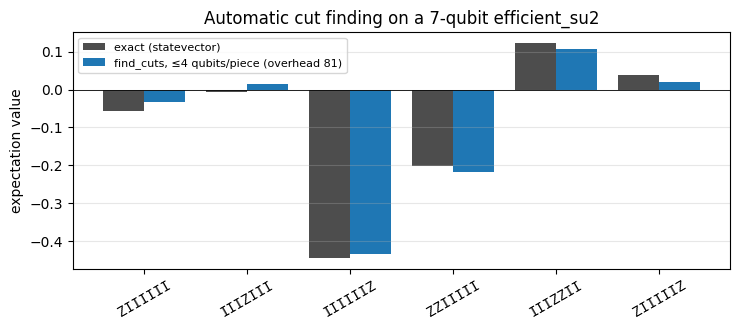

In [18]:
qc7_moved = cut_wires(cut7)
obs7_exp = expand_observables(obs7, qc7, qc7_moved)
pp7 = partition_problem(qc7_moved, observables=obs7_exp)
print("subcircuit widths:", {k: v.num_qubits for k, v in pp7.subcircuits.items()})

sub7, coeffs7 = generate_cutting_experiments(pp7.subcircuits, pp7.subobservables, num_samples=1000)
print("subexperiments:", {k: len(v) for k, v in sub7.items()}, "| weight types:", {w.name for _, w in coeffs7})
res7 = {k: sampler.run(v, shots=4096).result() for k, v in sub7.items()}
rec7 = np.array(reconstruct_expectation_values(res7, coeffs7, pp7.subobservables))
compare_plot(obs7, exact7, {f"find_cuts, ≤4 qubits/piece (overhead {meta['sampling_overhead']:.0f})": rec7},
             "Automatic cut finding on a 7-qubit efficient_su2")

**Overhead vs. device size.** A scan over `qubits_per_subcircuit` shows the exponential cost. Each additional cut multiplies the
overhead by 9 (CX gate cut) or 16 (wire cut). We also compare searches with gate cuts only and with wire cuts only on the
messenger circuit from Section 6. For that circuit, a wire cut has the lower overhead.

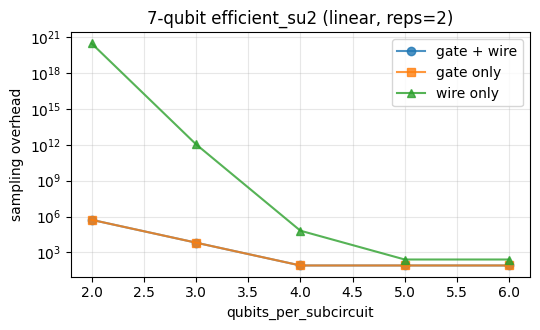

messenger circuit, gate only: cuts = [('Gate Cut', 6), ('Gate Cut', 10)], overhead = 81
messenger circuit, wire only: cuts = [('Wire Cut', 9)], overhead = 16


In [19]:
widths = [2, 3, 4, 5, 6]
ovs = {}
for name, kw in {"gate + wire": dict(gate_lo=True, wire_lo=True), "gate only": dict(gate_lo=True, wire_lo=False),
                 "wire only": dict(gate_lo=False, wire_lo=True)}.items():
    ovs[name] = [find_cuts(qc7, OptimizationParameters(seed=111, **kw), DeviceConstraints(k))[1]["sampling_overhead"]
                 for k in widths]

fig, ax = plt.subplots(figsize=(5.5, 3.4))
for (name, v), m in zip(ovs.items(), "os^"):
    ax.semilogy(widths, v, m + "-", label=name, alpha=.8)
ax.set_xlabel("qubits_per_subcircuit"); ax.set_ylabel("sampling overhead"); ax.grid(alpha=.3, which="both")
ax.set_title("7-qubit efficient_su2 (linear, reps=2)"); ax.legend(); plt.tight_layout(); plt.show()

for name, kw in {"gate only": dict(gate_lo=True, wire_lo=False), "wire only": dict(gate_lo=False, wire_lo=True)}.items():
    _, m = find_cuts(qc_w_plain, OptimizationParameters(seed=111, **kw), DeviceConstraints(3))
    print(f"messenger circuit, {name:9s}: cuts = {m['cuts']}, overhead = {m['sampling_overhead']:.0f}")

## 8. Summary, notes and references

* **QPD:** $\mathcal U=\sum_i a_i\mathcal F_i$ with local channels $\mathcal F_i$. The cost of one cut is $\kappa^2=(\sum_i|a_i|)^2$:
  9 for CX/CZ, $(1+2|\sin\theta|)^2$ for $R_{ZZ}(\theta)$, 49 for SWAP and 16 for an LO wire cut. The costs of several cuts multiply.
* **Gate cutting (width):** `partition_problem(circuit, partition_labels, observables)` → `generate_cutting_experiments(subcircuits,
  subobservables, num_samples)` → run the list of each partition with a `SamplerV2` → `reconstruct_expectation_values(results_dict,
  coefficients, subobservables)`. The reconstruction agrees with the exact values within the shot noise.
* **Gate cutting (depth):** `cut_gates(circuit, gate_ids)` without partitions removes long-range gates and their SWAP gates.
  The ISA circuits become shallower.
* **Wire cutting:** `CutWire` + `cut_wires` + `expand_observables`, or an explicit `Move` to a new qubit. A wire cut costs less than
  gate cuts when one qubit interacts with many qubits on both sides.
* **Automatic cuts:** `find_cuts(circuit, OptimizationParameters(...), DeviceConstraints(qubits_per_subcircuit))` returns the cut circuit
  and `metadata["sampling_overhead"]`.

**Notes on the installed version (0.10.0)**

* Observables must be a `PauliList` without coefficients or phases. For a `SparsePauliOp`, apply the `.coeffs` yourself after reconstruction.
* `cut_gates`, and therefore `find_cuts`, rejects circuits with classical bits. Add measurements only after cutting.
  `find_cuts` also rejects gates on more than 2 qubits.
* The qubit that `cut_wires` adds is a plain `Qubit` without a register, so drawings show it as a plain index. It is inserted at the index
  of the cut wire and carries the part *before* the cut. The original qubit and all later qubits move up by one index.
  Use `expand_observables` and do not map the observables by hand.
* In Pauli labels, the **rightmost** character is qubit 0. In the partition-label string, position $i$ from the left is qubit $i$
  (`"AAABBB"`). The two conventions run in opposite directions.
* `generate_cutting_experiments` with `num_samples=np.inf` enumerates all combinations of terms. Their number grows as $6^{n}$ for $n$ CX cuts.
  Use a finite `num_samples` when there are many cuts.
* Subexperiments contain mid-circuit measurements, and resets for wire cuts. The target must support dynamic circuits.
* The reconstruction also multiplies the readout errors of the QPD mid-circuit measurements by $\kappa$. Mitigate them, for example
  with `mthree`, if precision is important.
* `qiskit_ibm_runtime.SamplerV2` is deprecated in runtime 0.50. For local fake-backend runs, use
  `qiskit_aer.primitives.SamplerV2.from_backend(fake)`.

**References** (documentation pages)

1. Explanatory material, circuit cutting: <https://qiskit.github.io/qiskit-addon-cutting/explanation/index.html>
2. Tutorial, Gate Cutting to Reduce Circuit Width: <https://qiskit.github.io/qiskit-addon-cutting/tutorials/01_gate_cutting_to_reduce_circuit_width.html>
3. Tutorial, Gate Cutting to Reduce Circuit Depth: <https://qiskit.github.io/qiskit-addon-cutting/tutorials/02_gate_cutting_to_reduce_circuit_depth.html>
4. Tutorial, Wire Cutting Phrased as a Two-Qubit Move Instruction: <https://qiskit.github.io/qiskit-addon-cutting/tutorials/03_wire_cutting_via_move_instruction.html>
5. Tutorial, Automatically find cuts: <https://qiskit.github.io/qiskit-addon-cutting/tutorials/04_automatic_cut_finding.html>
6. How-to, How to place wire cuts using a single-qubit CutWire instruction: <https://qiskit.github.io/qiskit-addon-cutting/how-tos/how_to_specify_cut_wires.html>
7. API reference, `qiskit_addon_cutting`: <https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.html>
8. API reference, `qiskit_addon_cutting.qpd`: <https://qiskit.github.io/qiskit-addon-cutting/apidocs/qiskit_addon_cutting.qpd.html>
9. IBM Quantum documentation, circuit cutting API (`qiskit_addon_cutting`): <https://quantum.cloud.ibm.com/docs/en/api/qiskit-addon-cutting/qiskit-addon-cutting>

In [20]:
print(f"Total notebook compute time: {time.perf_counter() - T_START:.1f} s")

Total notebook compute time: 46.6 s
